# Adult income

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, silhouette_score
from sklearn.cluster import KMeans
from sklearn import metrics
from sklearn import tree
SEED = 42
TARGET = 'income'

df = pd.read_csv('Preprocessed_dataset.csv')

y = df[TARGET]
X_raw = df.drop(columns=[TARGET])

X = pd.get_dummies(X_raw)
X_cl = X_raw.select_dtypes(include='number')

fn = X.columns.tolist()
cn = df[TARGET].unique()
print(X.shape, X_cl.shape)
df.head()

(45985, 111) (45985, 6)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
0,0.109589,Private,0.599816,11th,0.400000,Never-married,Machine-op-inspct,Own-child,Black,Male,0.000000,0.0,0.397959,United-States,<=50K,Young,Full-time
1,0.287671,Private,0.402918,HS-grad,0.533333,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.000000,0.0,0.500000,United-States,<=50K,Adult,Overtime
2,0.150685,Local-gov,0.683958,Assoc-acdm,0.733333,Married-civ-spouse,Protective-serv,Husband,White,Male,0.000000,0.0,0.397959,United-States,>50K,Adult,Full-time
3,0.369863,Private,0.526083,Some-college,0.600000,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,0.777174,0.0,0.397959,United-States,>50K,Adult,Full-time
4,0.232877,Private,0.571691,10th,0.333333,Never-married,Other-service,Not-in-family,White,Male,0.000000,0.0,0.295918,United-States,<=50K,Adult,Part-time


# [1] Problem




### Project goal (Phase 1)
The goal of this project is to apply **data mining techniques** to the **Adult Income dataset**.  
Specifically, the objective is to perform **classification** (to predict whether an individual's income is `<=50K` or `>50K`) and **clustering** (to group individuals with similar personal and work-related characteristics).

This project is important because income prediction can support **decision-making** and help identify useful patterns in **business and social research**.

**The problem:** Predicting whether a person earns a high income is a common question in social and economic studies. In this project we want to predict whether an adult's annual income is **less than or equal to \$50,000** or **more than \$50,000**, using demographic, educational, and employment characteristics such as age, education level, occupation, marital status, and hours worked per week.

**Why it is important:** Income is influenced by many factors, not just one. Studying how education, occupation, age, and working hours relate to income helps us understand which factors are linked to higher income levels. These patterns can also be used to build a model that predicts a person's income level automatically, which can support analysis in areas such as economic research and social studies.

# [2] Data Mining Task


**Classification task:** This is a supervised learning task. Using the attributes of each person (such as age, education, occupation, marital status, and hours worked per week), we build a Decision Tree model that predicts the class label **income**, which has two classes: `<=50K` and `>50K`. The model learns from examples where the income is already known, then is tested on examples it has not seen before.

**Clustering task:** This is an unsupervised learning task. We use the K-means algorithm to group people with similar characteristics into clusters, **without using the income label**. The goal is to discover natural groups in the data and see which characteristics each group shares.

# [3] Data


## Dataset Source

The dataset was obtained from Kaggle:

[Adult Income Dataset](https://www.kaggle.com/datasets/wenruliu/adult-income-dataset)

## Dataset Description
The Adult Income dataset contains **48,842 records (rows)** and **15 attributes (columns)**. Among these attributes, **14 are input features** and **1 is the class attribute (income)**. The input features include **6 numerical attributes** and **8 categorical attributes**, representing demographic, educational, and employment-related information about individuals.

### Target Attribute

The **target attribute** is income, which has two classes:

- `<=50K`
- `>50K`


In [2]:
df_raw = pd.read_csv("Raw_dataset.csv")

### Number of Records and Attributes

In [3]:
print("Number of records:", df_raw.shape[0])
print("Number of attributes:", df_raw.shape[1])

Number of records: 48842
Number of attributes: 15


### Data Types of Attributes

In [4]:
print("Data types of attributes:")
print(df_raw.dtypes)

Data types of attributes:
age                 int64
workclass          object
fnlwgt              int64
education          object
educational-num     int64
marital-status     object
occupation         object
relationship       object
race               object
gender             object
capital-gain        int64
capital-loss        int64
hours-per-week      int64
native-country     object
income             object
dtype: object


In [5]:
class_column = "income"
print("Class Attribute:", class_column)
print("Class Values:", df_raw[class_column].unique())

Class Attribute: income
Class Values: ['<=50K' '>50K']


In [6]:
print("Number of instances per class:")
print(df_raw[class_column].value_counts())

Number of instances per class:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64


In [7]:
print("Sample from the raw Dataset:")
df_raw.head()

Sample from the raw Dataset:


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


## Data Analysis (Phase 2)


## Choosing Numeric Attribute

In [8]:
numeric_cols=["age","fnlwgt","educational-num","capital-gain","capital-loss","hours-per-week"]
numeric_cols

['age',
 'fnlwgt',
 'educational-num',
 'capital-gain',
 'capital-loss',
 'hours-per-week']

## Five number & Statistical Summary

In [9]:
five_num = df_raw[numeric_cols].describe().loc[['min', '25%', '50%', '75%', 'max']]
display(five_num)
sammary=df_raw[numeric_cols].describe()
display(sammary)

,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
min,17.0,12285.0,1.0,0.0,0.0,1.0
25%,28.0,117550.5,9.0,0.0,0.0,40.0
50%,37.0,178144.5,10.0,0.0,0.0,40.0
75%,48.0,237642.0,12.0,0.0,0.0,45.0
max,90.0,1490400.0,16.0,99999.0,4356.0,99.0


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


**Age:** Min 17, Q1 28, median 37, Q3 48, max 90. Most individuals are between 28 and 48 years old, and the maximum is far above Q3, so values above 78 may be considered potential outliers.

**fnlwgt:** Min 12,285, Q1 117,550, median 178,145, Q3 237,642, max 1,490,400. The maximum is much larger than Q3, which indicates high variability and possible outliers.

**Education-num:** Min 1, Q1 9, median 10, Q3 12, max 16. Most individuals have education levels between 9 and 12, and the low values (below 4.5) may be potential outliers.

**Hours-per-week:** Min 1, Q1 40, median 40, Q3 45, max 99. Most individuals work around 40 hours per week, with values at both extremes indicating potential outliers.

**Capital-gain and Capital-loss:** Min, Q1, median and Q3 are all 0, while the maximums are 99,999 and 4,356. Most values are 0, and a small number of very large values suggest the presence of outliers and a highly skewed distribution.

The five-number summary shows the center and spread of each numerical attribute, helping identify skewness and potential outliers.

## Histogram

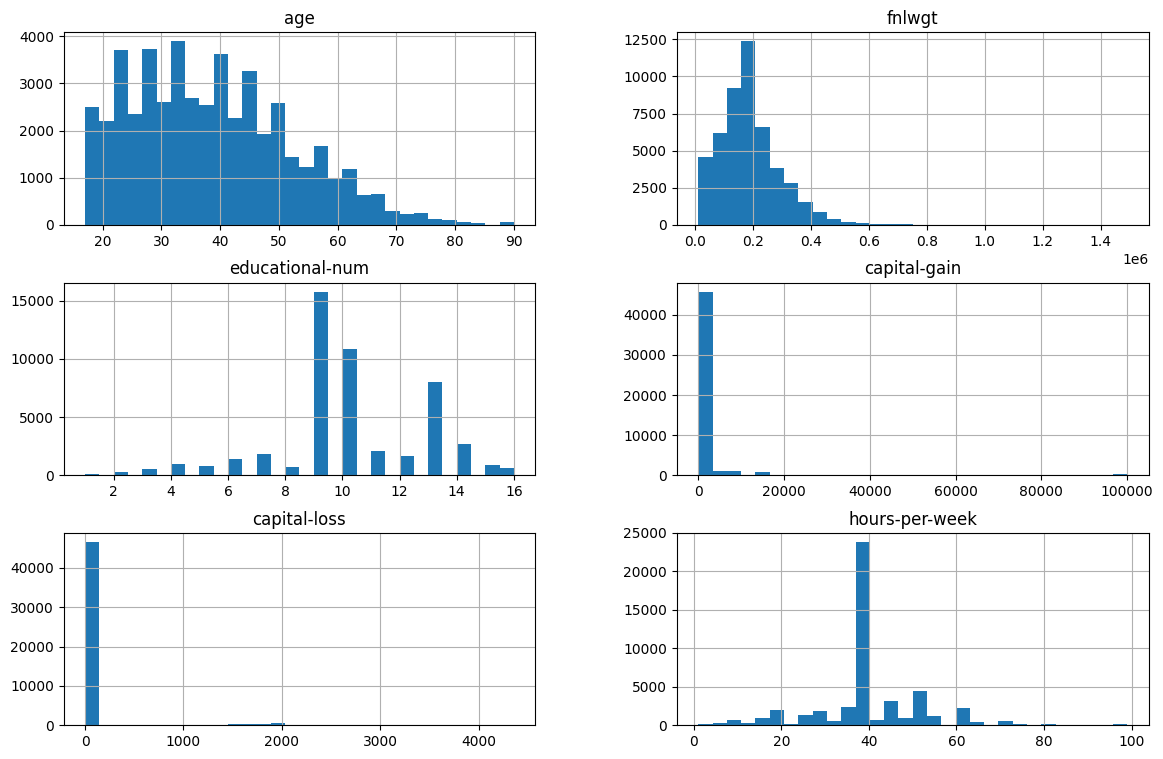

In [10]:
df_raw[numeric_cols].hist(bins=30, figsize=(14, 9))
plt.show()

The histograms show that capital-gain and capital-loss are very right skewed. Almost all the values are in the first bar at 0, and only a few small bars appear far to the right (around 100000 for capital-gain and between 1500 and 2500 for capital-loss). fnlwgt is also right skewed, because most values are between 0 and 0.4 million and there is a long tail that goes up to about 1.5 million. Age is a little right skewed, most people are between 20 and 50 and the number of people gets smaller after 60. educational-num has high bars at 9, 10 and 13, and hours-per-week has a very big peak at 40 hours with few values near 99. Because capital-gain, capital-loss and fnlwgt have long right tails and extreme values, we will apply log transformation on them.

## Boxplots

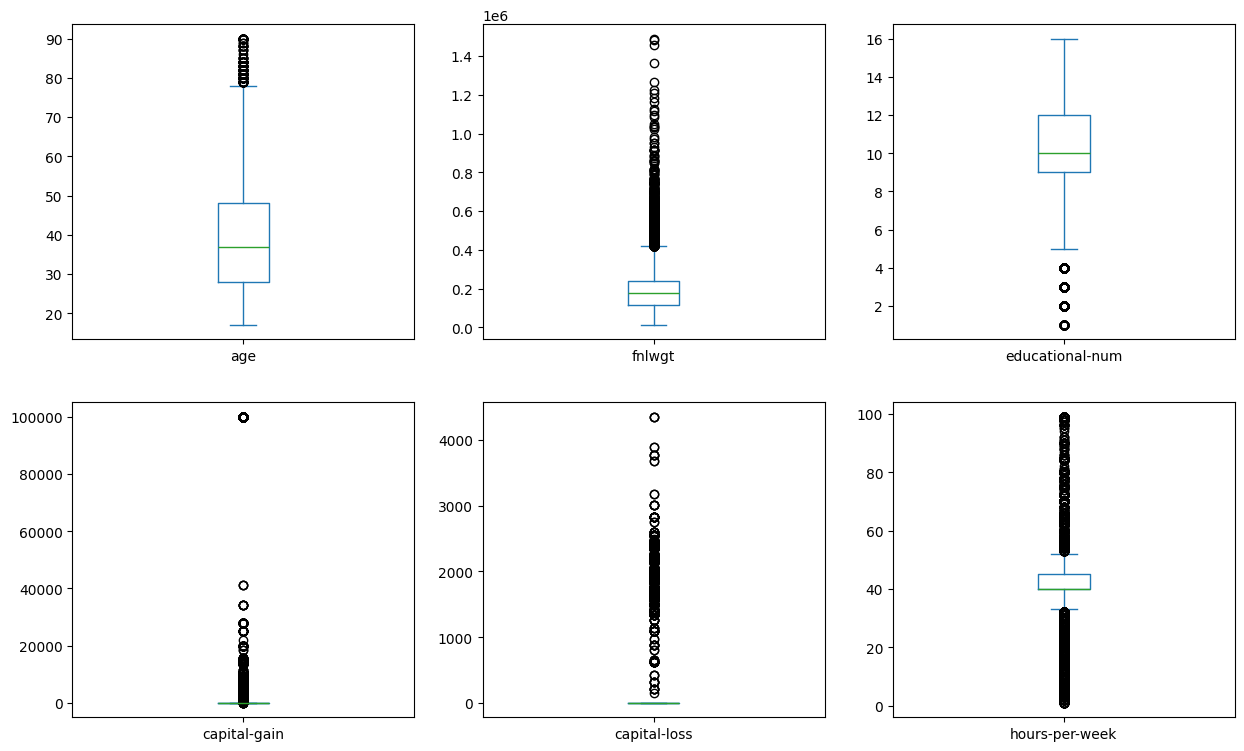

In [11]:
df_raw[numeric_cols].plot(kind='box', subplots=True, layout=(2, 3), figsize=(15, 9))
plt.show()

The boxplots show outliers in all numeric attributes. Age has a few outliers above 78, fnlwgt has many high outliers up to about 1.5 million, and educational-num has low outliers between 1 and 4. For capital-gain and capital-loss the box is flat at 0, so every value above 0 is an outlier, with capital-gain reaching about 100000. hours-per-week has a narrow box between 40 and 45, so values below about 32 and above about 52 are outliers. These are real values, so we kept them and reduced their effect with log transformation and normalization.

## Outlier Analysis

In [12]:
Q1 = df_raw[numeric_cols].quantile(0.25)
Q3 = df_raw[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = ((df_raw[numeric_cols] < lower) | (df_raw[numeric_cols] > upper)).sum()
pd.DataFrame({'lower': lower, 'upper': upper, 'outliers': outliers})

,lower,upper,outliers
age,-2.00,78.00,216
fnlwgt,-62586.75,417779.25,1453
educational-num,4.50,16.50,1794
capital-gain,0.00,0.00,4035
capital-loss,0.00,0.00,2282
hours-per-week,32.50,52.50,13496


The boxplots and the IQR method show many outliers in capital-gain, capital-loss and hours-per-week. For capital-gain and capital-loss the IQR is 0, so any value that is not 0 is counted as an outlier. For hours-per-week the IQR is small (40 to 45), so people who work part time or long hours are counted as outliers. These values are real and make sense (for example working 60 hours or having capital gain), so we did not remove them. We will reduce their effect with log transformation and normalization instead.

## Scatter Plot

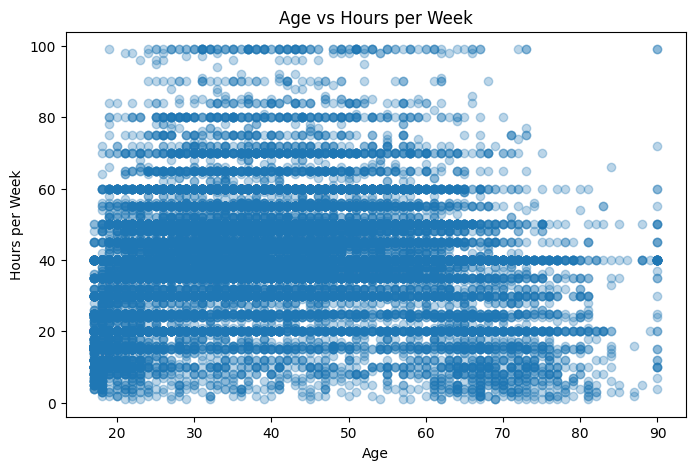

In [13]:
plt.figure(figsize=(8,5))
plt.scatter(df_raw['age'], df_raw['hours-per-week'], alpha=0.3)
plt.xlabel('Age')
plt.ylabel('Hours per Week')
plt.title('Age vs Hours per Week')

plt.show()

There is no strong relationship between age and hours-per-week. Most individuals are between 20–60 years old and work around 35–45 hours per week. Some extreme observations can be seen, such as very old individuals with unusually high working hours. These observations should be examined during preprocessing for possible outliers.

## Bar Plot of Categorical Attribute

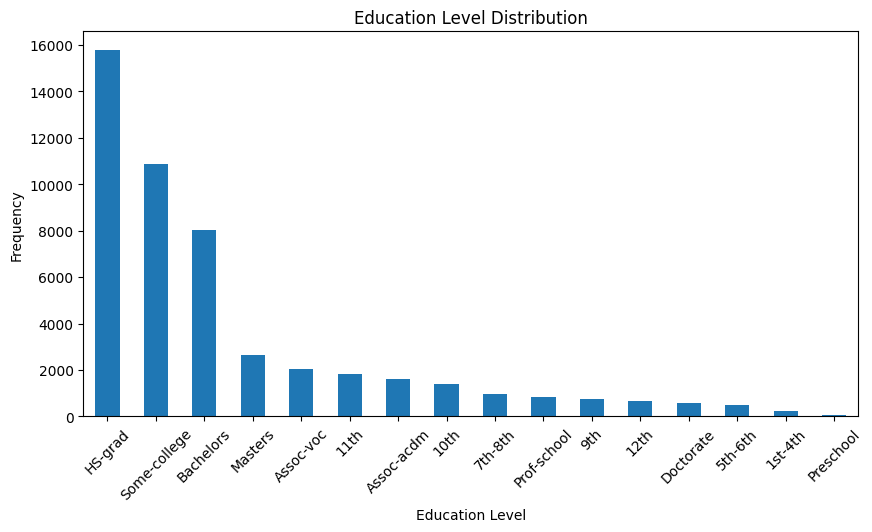

In [14]:
df_raw['education'].value_counts().plot(kind='bar', figsize=(10, 5))
plt.xlabel('Education Level')
plt.ylabel('Frequency')
plt.title('Education Level Distribution')
plt.xticks(rotation=45)

plt.show()

The bar plot shows that HS-grad is the most common education level, then Some-college and Bachelors. Levels like Preschool and 1st-4th have very few records, so the categories are not balanced.

## Missing Values Analysis

In [15]:
missing = (df_raw == '?').sum()
missing = missing[missing > 0]
missing_table = pd.DataFrame({'Attribute': missing.index, 'Missing Count': missing.values, 'Missing Percentage': (missing.values / len(df_raw) * 100).round(2)})
missing_table

,Attribute,Missing Count,Missing Percentage
0,workclass,2799,5.73
1,occupation,2809,5.75
2,native-country,857,1.75


There are 3 attributes with missing values: occupation (2,809, 5.75%), workclass (2,799, 5.73%) and native-country (857, 1.75%). These missing values should be handled appropriately, as they may affect the accuracy and reliability of the analysis results.


## Class Label Plot

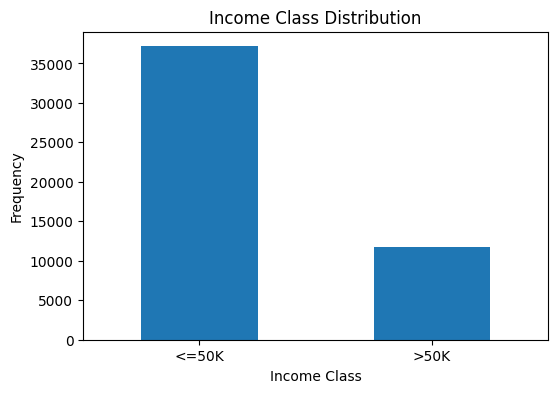

In [16]:
plt.figure(figsize=(6,4))
df_raw['income'].astype(str).str.strip().value_counts().plot(kind='bar')
plt.xlabel('Income Class')
plt.ylabel('Frequency')
plt.title('Income Class Distribution')
plt.xticks(rotation=0)

plt.show()

The income classes are clearly imbalanced. Most individuals belong to the <=50K class, while the >50K class contains considerably fewer observations. This imbalance may cause the model to favor the majority class, so it should be considered during preprocessing and model development.

# [4] Data Preprocessing


## Data Preprocessing (Phase 2)




In [17]:
df_preprocessed = df_raw.copy()

## Missing Values Handling

In [18]:
df_preprocessed = df_preprocessed.replace('?', np.nan)
before = df_preprocessed.isna().sum()
before

,0
age,0
workclass,2799
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,2809
relationship,0
race,0
gender,0


In [19]:
df_preprocessed = df_preprocessed.dropna(subset=['occupation'])
df_preprocessed['native-country'] = df_preprocessed['native-country'].fillna(df_preprocessed['native-country'].mode()[0])
print(df_preprocessed.shape)
df_preprocessed.isna().sum()

(46033, 15)


,0
age,0
workclass,0
fnlwgt,0
education,0
educational-num,0
marital-status,0
occupation,0
relationship,0
race,0
gender,0


Missing values were found in workclass, occupation, and native-country. Rows with missing occupation (2,809 rows) were removed, which also removed all rows with missing workclass because they were among these rows. Missing native-country values were replaced with the mode. After handling, the dataset had 46,033 rows and no missing values remained.

## Noise Removal

In [20]:
print("Duplicate rows before:", df_preprocessed.duplicated().sum())
df_preprocessed = df_preprocessed.drop_duplicates()
print("Duplicate rows after:", df_preprocessed.duplicated().sum())
print(df_preprocessed.shape)

Duplicate rows before: 48
Duplicate rows after: 0
(45985, 15)


We checked the dataset for duplicate rows because repeated records are noise. They do not add new information and give the same record more weight than the others. We found 48 duplicate rows and removed them using drop_duplicates(). Now the dataset has 0 duplicates and 45985 rows.

## Variable Transformation

In [21]:
cols = ['fnlwgt', 'capital-gain', 'capital-loss']
before = df_preprocessed[cols].skew()
df_preprocessed[cols] = np.log1p(df_preprocessed[cols])
pd.DataFrame({'before': before, 'after': df_preprocessed[cols].skew()}).round(2)

,before,after
fnlwgt,1.44,-0.83
capital-gain,11.68,3.08
capital-loss,4.51,4.27


The histograms showed strong right skewness in fnlwgt, capital-gain and capital-loss, so we applied log transformation using np.log1p because these columns have 0 values. Skewness of capital-gain went from 11.68 to 3.08 and fnlwgt from 1.44 to -0.83. capital-loss only went from 4.51 to 4.27 because most of its values are 0. Age, educational-num and hours-per-week were not changed because they were only a little skewed.


## Discretization

In [23]:
df_preprocessed['age_group'] = pd.cut(
    df_raw['age'],
    [16, 25, 45, 60, 100],
    labels=['Young', 'Adult', 'Middle-aged', 'Senior']
)

df_preprocessed['hours_category'] = pd.cut(
    df_raw['hours-per-week'],
    [0, 34, 40, 99],
    labels=['Part-time', 'Full-time', 'Overtime']
)

print(
    df_preprocessed['age_group'].value_counts(),
    df_preprocessed['hours_category'].value_counts(),
    sep='\n\n'
)

age_group
Adult          24017
Middle-aged    10546
Young           8522
Senior          2900
Name: count, dtype: int64

hours_category
Full-time    24840
Overtime     14017
Part-time     7128
Name: count, dtype: int64


We discretized age into a new attribute age_group because age groups are easier to understand than exact ages. We used four groups: Young (17-25), Adult (26-45), Middle-aged (46-60) and Senior (61+). We also created hours_category from hours-per-week using three groups: Part-time (34 hours or less), Full-time (35-40 hours) and Overtime (more than 40 hours). Most people are in the Adult group and the Senior group is the smallest.

## Normalization

In [24]:
print(df_preprocessed[numeric_cols].describe().loc[['min', 'max']].round(2))
scaler = MinMaxScaler()
df_preprocessed[numeric_cols] = scaler.fit_transform(df_preprocessed[numeric_cols])
df_preprocessed[numeric_cols].describe().loc[['min', 'max']]

      age  fnlwgt  educational-num  capital-gain  capital-loss  hours-per-week
min  17.0    9.51              1.0          0.00          0.00             1.0
max  90.0   14.21             16.0         11.51          8.38            99.0


,age,fnlwgt,educational-num,capital-gain,capital-loss,hours-per-week
min,0.0,0.0,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0,1.0,1.0


The numeric attributes had very different ranges, for example hours-per-week is from 1 to 99 and educational-num is from 1 to 16. So we used Min-Max normalization on the 6 numeric attributes. Now all of them are between 0 and 1, so they can be compared better and no attribute is bigger just because of its scale.

## Raw Dataset Snapshot

In [25]:
print(df_raw.shape)
df_raw.head(10)

(48842, 15)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K
5,34,Private,198693,10th,6,Never-married,Other-service,Not-in-family,White,Male,0,0,30,United-States,<=50K
6,29,?,227026,HS-grad,9,Never-married,?,Unmarried,Black,Male,0,0,40,United-States,<=50K
7,63,Self-emp-not-inc,104626,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,3103,0,32,United-States,>50K
8,24,Private,369667,Some-college,10,Never-married,Other-service,Unmarried,White,Female,0,0,40,United-States,<=50K
9,55,Private,104996,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,10,United-States,<=50K


The raw dataset still has 48842 rows and 15 columns and still has the ? values, so it was not changed.

## Preprocessed Dataset Snapshot

In [26]:
print(df_preprocessed.shape)
df_preprocessed.head(10)

(45985, 17)


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
0,0.109589,Private,0.599816,11th,0.400000,Never-married,Machine-op-inspct,Own-child,Black,Male,0.000000,0.0,0.397959,United-States,<=50K,Young,Full-time
1,0.287671,Private,0.402918,HS-grad,0.533333,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.000000,0.0,0.500000,United-States,<=50K,Adult,Overtime
2,0.150685,Local-gov,0.683958,Assoc-acdm,0.733333,Married-civ-spouse,Protective-serv,Husband,White,Male,0.000000,0.0,0.397959,United-States,>50K,Adult,Full-time
3,0.369863,Private,0.526083,Some-college,0.600000,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,0.777174,0.0,0.397959,United-States,>50K,Adult,Full-time
5,0.232877,Private,0.571691,10th,0.333333,Never-married,Other-service,Not-in-family,White,Male,0.000000,0.0,0.295918,United-States,<=50K,Adult,Part-time
7,0.630137,Self-emp-not-inc,0.435365,Prof-school,0.933333,Married-civ-spouse,Prof-specialty,Husband,White,Male,0.698384,0.0,0.316327,United-States,>50K,Senior,Part-time
8,0.095890,Private,0.703655,Some-college,0.600000,Never-married,Other-service,Unmarried,White,Female,0.000000,0.0,0.397959,United-States,<=50K,Young,Full-time
9,0.520548,Private,0.436115,7th-8th,0.200000,Married-civ-spouse,Craft-repair,Husband,White,Male,0.000000,0.0,0.091837,United-States,<=50K,Middle-aged,Part-time
10,0.657534,Private,0.555885,HS-grad,0.533333,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0.761493,0.0,0.397959,United-States,>50K,Senior,Full-time
11,0.260274,Federal-gov,0.585936,Bachelors,0.800000,Married-civ-spouse,Adm-clerical,Husband,White,Male,0.000000,0.0,0.397959,United-States,<=50K,Adult,Full-time


The preprocessed dataset has 45985 rows and 17 columns (we added age_group and hours_category). It has no missing values, no duplicate rows after noise removal, the numeric attributes are between 0 and 1, and the skewed attributes are log transformed.

## Preprocessing Summary

We applied five preprocessing techniques. First, missing values in occupation, workclass, and native-country were handled by removing some rows and replacing missing values with the mode. Second, 48 duplicate rows were removed as noise removal. Third, log transformation was applied to fnlwgt, capital-gain, and capital-loss to reduce right skewness. Fourth, age and hours-per-week were discretized into groups (age_group and hours_category) to make them easier to interpret. Finally, Min-Max normalization was applied to the numeric attributes so their values are between 0 and 1.

After preprocessing, the dataset had no missing values, no duplicate rows, lower skewness, normalized numeric features, and clearer groups, making it more suitable.

In [27]:
df_preprocessed.to_csv('Preprocessed_dataset.csv', index=False)

In [28]:
print(df.shape)
print(df.dtypes)
print(y.value_counts())
df.sample(5, random_state=SEED)

(45985, 17)
age                float64
workclass           object
fnlwgt             float64
education           object
educational-num    float64
marital-status      object
occupation          object
relationship        object
race                object
gender              object
capital-gain       float64
capital-loss       float64
hours-per-week     float64
native-country      object
income              object
age_group           object
hours_category      object
dtype: object
income
<=50K    34569
>50K     11416
Name: count, dtype: int64


,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income,age_group,hours_category
39304,0.123288,Private,0.552648,Assoc-acdm,0.733333,Married-civ-spouse,Adm-clerical,Own-child,White,Female,0.0,0.0,0.397959,United-States,<=50K,Adult,Full-time
18306,0.273973,Private,0.676634,HS-grad,0.533333,Never-married,Exec-managerial,Own-child,White,Male,0.0,0.0,0.602041,United-States,<=50K,Adult,Overtime
6916,0.410959,Private,0.580520,HS-grad,0.533333,Separated,Machine-op-inspct,Not-in-family,White,Male,0.0,0.0,0.438776,United-States,<=50K,Middle-aged,Overtime
42746,0.424658,Self-emp-inc,0.760049,10th,0.333333,Married-civ-spouse,Exec-managerial,Husband,White,Male,0.0,0.0,0.397959,United-States,<=50K,Middle-aged,Full-time
38147,0.301370,State-gov,0.393383,HS-grad,0.533333,Divorced,Adm-clerical,Unmarried,White,Female,0.0,0.0,0.397959,United-States,<=50K,Adult,Full-time


**Size:** The preprocessed dataset contains **45,985 records** and **17 columns** (16 attributes and 1 class label).

**Attributes:**
- **Numeric (6):** age, fnlwgt, educational-num, capital-gain, capital-loss, hours-per-week (scaled between 0 and 1 in Phase 2).
- **Categorical (10):** workclass, education, marital-status, occupation, relationship, race, gender, native-country, plus two groups created in Phase 2: age_group and hours_category.

**Class label:** income, with two classes:
- `<=50K`: 34,569 records (about 75%)
- `>50K`: 11,416 records (about 25%)

The classes are imbalanced, since most people belong to `<=50K`.

# [5] Data Mining Technique

## 5.1 Classification: Decision Tree
We use the DecisionTreeClassifier from sklearn.tree [3] to predict the class label income (<=50K / >50K), because decision trees handle both numeric and categorical attributes and produce a tree we can read to see which attributes separate the two classes. We build two models with different attribute selection measures: the Gini index, DecisionTreeClassifier(criterion="gini"), which is the default, and information gain, DecisionTreeClassifier(criterion="entropy"). Scikit-learn only accepts numerical data, so the categorical attributes are encoded with pd.get_dummies. For each measure, the data is split with train_test_split into three partitions (90/10, 80/20, 70/30) with random_state=42. The models are evaluated with metrics.accuracy_score, confusion_matrix and ConfusionMatrixDisplay, and the tree is visualized with tree.plot_tree.

## 5.2 Clustering: K-means


We selected K-means because it groups records with similar numerical characteristics without using the target label.
The clustering uses the six numerical features of the preprocessed dataset (X_cl), which are already scaled between 0 and 1. The target column income is excluded because clustering is an unsupervised learning task.

The clustering is done with KMeans from sklearn.cluster (with n_init=10 and random_state=42). The average Silhouette width is computed with silhouette_score from sklearn.metrics, and the total within-cluster sum of squares is taken from the inertia_ attribute of the fitted model and plotted for the Elbow method. To visualize the clusters, the data is projected to two dimensions with PCA from sklearn.decomposition, and the plots are made with matplotlib.

**Choice of K:** We compare K = 2, 3, and 4. We started with K = 2 because the dataset has two income classes, and we added K = 3 and K = 4 to check whether more natural groups appear. We did not use larger values because they would split the data into many small clusters that are hard to interpret. For each K we calculate the average Silhouette width (higher is better) and the total within-cluster sum of squares (lower means tighter clusters).
**Best K (majority rule):** Silhouette gives K=3 (0.5541, vs 0.5068 for K=2 and 0.2822 for K=4). The Elbow plot also points to K=3: the total within-cluster SS drops by about 1,680 from K=2 to K=3 but only by about 900 from K=3 to K=4. Both measures agree, so K=3 is the optimal number of clusters. K=4 is rejected because it splits the large dense group by age and the Silhouette drops sharply.

# [6] Evaluation and Comparison

## 6.1 Classification - Gini

Accuracy (90/10): 0.80734942378778
[[3030  456]
 [ 430  683]]


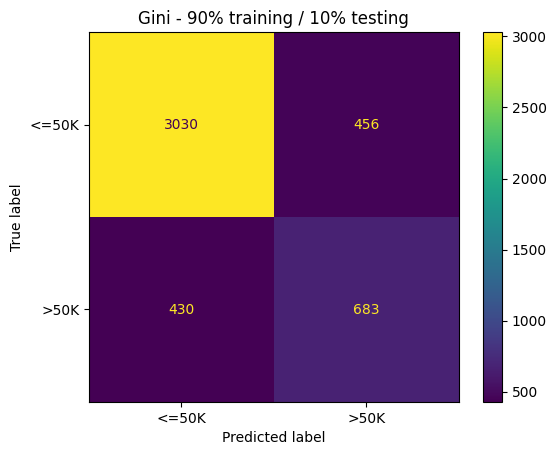

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

clf1 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf1 = clf1.fit(X_train, y_train)
y_pred = clf1.predict(X_test)

acc1 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (90/10):", acc1)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf1, X_test, y_test, display_labels=cn)
plt.title("Gini - 90% training / 10% testing")
plt.show()

**Interpretation (90/10):** The accuracy is 80.73%. The model correctly classified 3030 of 3486 `<=50K` cases (about 87%) but only 683 of 1113 `>50K` cases (about 61%). It makes more mistakes on the `>50K` class.


Accuracy (80/20): 0.8013482657388279
[[6024  948]
 [ 879 1346]]


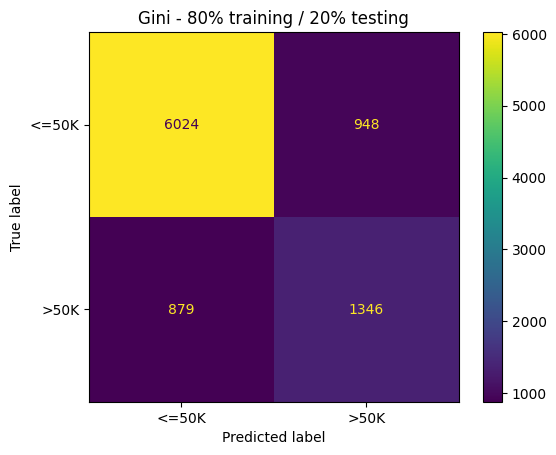

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

clf2 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf2 = clf2.fit(X_train, y_train)
y_pred = clf2.predict(X_test)

acc2 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (80/20):", acc2)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf2, X_test, y_test, display_labels=cn)
plt.title("Gini - 80% training / 20% testing")
plt.show()

**Interpretation (80/20):** The accuracy is 80.13%, the lowest of the three partitions. The model correctly classified 6024 of 6972 `<=50K` cases (about 86%) but only 1346 of 2225 `>50K` cases (about 60%).

Accuracy (70/30): 0.8105972745723398
[[9082 1307]
 [1306 2101]]


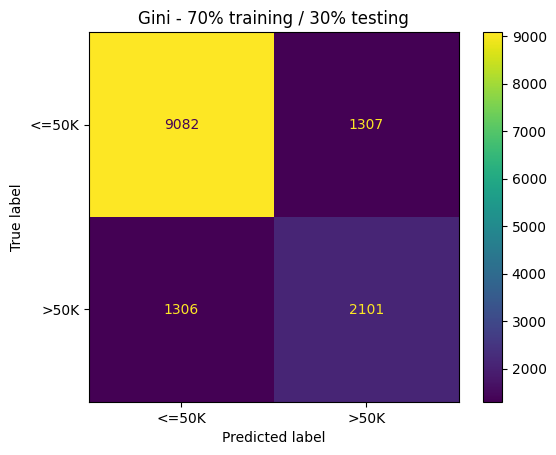

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

clf3 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf3 = clf3.fit(X_train, y_train)
y_pred = clf3.predict(X_test)

acc3 = metrics.accuracy_score(y_test, y_pred)
print("Accuracy (70/30):", acc3)
print(confusion_matrix(y_test, y_pred))
ConfusionMatrixDisplay.from_estimator(clf3, X_test, y_test, display_labels=cn)
plt.title("Gini - 70% training / 30% testing")
plt.show()

**Interpretation (70/30):** The accuracy is 81.06%, the highest of the three partitions. The model correctly classified 9082 of 10389 `<=50K` cases (about 87%) and 2101 of 3407 `>50K` cases (about 62%).

In [32]:
gini_table = pd.DataFrame(
    [[round(acc1, 4), round(acc2, 4), round(acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Accuracy"])
gini_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8073,0.8013,0.8106


**Interpretation of the Gini results:** The best Gini accuracy is obtained with the 70/30 partition (81.06%), followed by 90/10 (80.73%) and 80/20 (80.13%). The difference between the partitions is less than 1%, so the partition size has little effect on the Gini tree. In all partitions the model predicts the `<=50K` class (87%) better than the `>50K` class (61%) because the dataset is imbalanced (about 75% of the records are `<=50K`).

## 6.2 Classification - Entropy

### Entropy - 90% training / 10% testing

Accuracy (90/10): 0.8043052837573386
Accuracy (90/10) in %: 80.43
[[3007  479]
 [ 421  692]]


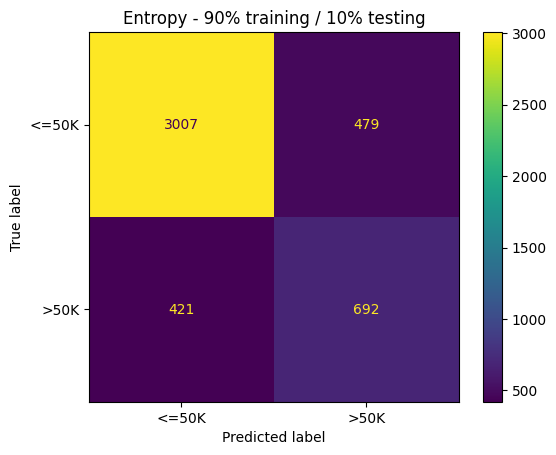

In [33]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.1, random_state=42)

entropy_clf1 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf1 = entropy_clf1.fit(X_train_e, y_train_e)
entropy_pred1 = entropy_clf1.predict(X_test_e)

entropy_acc1 = metrics.accuracy_score(y_test_e, entropy_pred1)
print("Accuracy (90/10):", entropy_acc1)
print("Accuracy (90/10) in %:", round(entropy_acc1 * 100, 2))

entropy_cm1 = confusion_matrix(y_test_e, entropy_pred1)
print(entropy_cm1)
ConfusionMatrixDisplay.from_estimator(entropy_clf1, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 90% training / 10% testing")
plt.show()

**Interpretation (90/10):** The accuracy is **80.43%**. The test set has 4,599 records: 3,699 were predicted correctly (3,007 + 692) and 900 were wrong. The model correctly classified 3,007 of 3,486 `<=50K` records (about 86%), but only 692 of 1,113 `>50K` records (about 62%). So the `>50K` class has many more errors: 421 high-income people were predicted as `<=50K`.

### Entropy - 80% training / 20% testing

Accuracy (80/20): 0.8083070566489072
Accuracy (80/20) in %: 80.83
[[6068  904]
 [ 859 1366]]


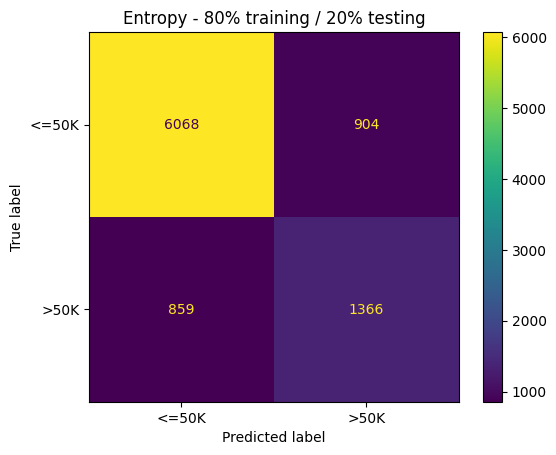

In [34]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.2, random_state=42)

entropy_clf2 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf2 = entropy_clf2.fit(X_train_e, y_train_e)
entropy_pred2 = entropy_clf2.predict(X_test_e)

entropy_acc2 = metrics.accuracy_score(y_test_e, entropy_pred2)
print("Accuracy (80/20):", entropy_acc2)
print("Accuracy (80/20) in %:", round(entropy_acc2 * 100, 2))

entropy_cm2 = confusion_matrix(y_test_e, entropy_pred2)
print(entropy_cm2)
ConfusionMatrixDisplay.from_estimator(entropy_clf2, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 80% training / 20% testing")
plt.show()

**Interpretation (80/20):** The accuracy is **80.83%**. Out of 9,197 test records, 7,434 were correct (6,068 + 1,366) and 1,763 were wrong. The model correctly classified 6,068 of 6,972 `<=50K` records (about 87%) and 1,366 of 2,225 `>50K` records (about 61%). Again, the `>50K` class is weaker(859 records predicted as `<=50K`).

### Entropy - 70% training / 30% testing

Accuracy (70/30): 0.8108872136851262
Accuracy (70/30) in %: 81.09
[[9081 1308]
 [1301 2106]]


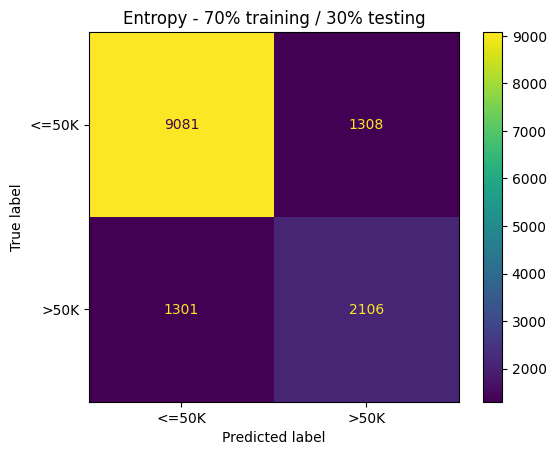

In [35]:
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X, y, test_size=0.3, random_state=42)

entropy_clf3 = DecisionTreeClassifier(criterion="entropy", random_state=42)
entropy_clf3 = entropy_clf3.fit(X_train_e, y_train_e)
entropy_pred3 = entropy_clf3.predict(X_test_e)

entropy_acc3 = metrics.accuracy_score(y_test_e, entropy_pred3)
print("Accuracy (70/30):", entropy_acc3)
print("Accuracy (70/30) in %:", round(entropy_acc3 * 100, 2))

entropy_cm3 = confusion_matrix(y_test_e, entropy_pred3)
print(entropy_cm3)
ConfusionMatrixDisplay.from_estimator(entropy_clf3, X_test_e, y_test_e, display_labels=cn)
plt.title("Entropy - 70% training / 30% testing")
plt.show()

**Interpretation (70/30):** The accuracy is **81.09%**, the highest of the three Entropy partitions. Out of 13,796 test records, 11,187 were correct (9,081 + 2,106) and 2,609 were wrong. The model correctly classified 9,081 of 10,389 `<=50K` records (about 87%) and 2,106 of 3,407 `>50K` records (about 62%). The pattern is the same as the other partitions: the `>50K` class is harder to predict.

### Entropy accuracy table

In [36]:
entropy_table = pd.DataFrame(
    [[round(entropy_acc1, 4), round(entropy_acc2, 4), round(entropy_acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Accuracy"])
entropy_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Accuracy,0.8043,0.8083,0.8109


**Interpretation of the Entropy results:** The best Entropy accuracy is with the **70/30** partition (81.09%), then 80/20 (80.83%), and the lowest is **90/10** (80.43%). So more training data did not give a better result here. The difference between the best and the worst partition is only about 0.66 percentage points, which is small.

One likely reason is that the 90/10 test set is the smallest (4,599 records), so its accuracy depends more on which records happen to be in it. Also, the tree is grown without any depth limit, so it learns the training data very closely in every partition, and adding more training records does not change the test accuracy much. In all partitions, about 86-87% of `<=50K` records are classified correctly but only about 61-62% of `>50K` records, because the dataset is imbalanced (about 75% `<=50K`).

## 6.3 Gini vs. Entropy Comparison


In [37]:
compare_table = pd.DataFrame(
    [[round(acc1, 4), round(acc2, 4), round(acc3, 4)],
     [round(entropy_acc1, 4), round(entropy_acc2, 4), round(entropy_acc3, 4)]],
    columns=["90% training / 10% testing", "80% training / 20% testing", "70% training / 30% testing"],
    index=["Gini", "Entropy"])
compare_table

,90% training / 10% testing,80% training / 20% testing,70% training / 30% testing
Gini,0.8073,0.8013,0.8106
Entropy,0.8043,0.8083,0.8109


The table shows that the two methods give very close accuracy in all partitions (all values are between 80.1% and 81.1%). Gini is better in the 90/10 partition, and Entropy is better in the 80/20 and 70/30 partitions. The details are below.

### Best method for each partition



In [38]:
partitions = ["90/10", "80/20", "70/30"]
gini_list = [acc1, acc2, acc3]
entropy_list = [entropy_acc1, entropy_acc2, entropy_acc3]

for i in range(3):
    if entropy_list[i] > gini_list[i]:
        winner = "Entropy"
    elif gini_list[i] > entropy_list[i]:
        winner = "Gini"
    else:
        winner = "Tie"
    difference = abs(entropy_list[i] - gini_list[i]) * 100
    print(partitions[i], "-> Gini:", round(gini_list[i] * 100, 2), "% | Entropy:", round(entropy_list[i] * 100, 2),
          "% | Better:", winner, "| Difference:", round(difference, 2), "percentage points")

90/10 -> Gini: 80.73 % | Entropy: 80.43 % | Better: Gini | Difference: 0.3 percentage points
80/20 -> Gini: 80.13 % | Entropy: 80.83 % | Better: Entropy | Difference: 0.7 percentage points
70/30 -> Gini: 81.06 % | Entropy: 81.09 % | Better: Entropy | Difference: 0.03 percentage points


### Best method overall

In [39]:
all_results = pd.Series({"Gini 90/10": acc1, "Gini 80/20": acc2, "Gini 70/30": acc3,
                         "Entropy 90/10": entropy_acc1, "Entropy 80/20": entropy_acc2, "Entropy 70/30": entropy_acc3})
print(all_results.sort_values(ascending=False))

print("\nAverage accuracy over the three partitions:")
print(compare_table.mean(axis=1))

Entropy 70/30    0.810887
Gini 70/30       0.810597
Entropy 80/20    0.808307
Gini 90/10       0.807349
Entropy 90/10    0.804305
Gini 80/20       0.801348
dtype: float64

Average accuracy over the three partitions:
Gini       0.806400
Entropy    0.807833
dtype: float64


Among the six tested configurations, the highest test accuracy is **Entropy with the 70/30 partition (81.09%)**. Gini with 70/30 is second (81.06%), only 4 correct records behind. Entropy is better in 2 of the 3 partitions, and its average accuracy over the three partitions is slightly higher than Gini's.

So **Entropy is the best-performing method among the configurations we tested**, but the differences are very small (less than 1 percentage point) so we cannot say that Entropy is clearly better than Gini in general. With a different random split, the order could change.

Also, accuracy alone does not show all the errors. Because about 75% of the records are `<=50K`, a model can get a high accuracy while still missing many `>50K` records. The confusion matrices show that both methods correctly find only about 61-62% of the `>50K` records.

### Comparison chart

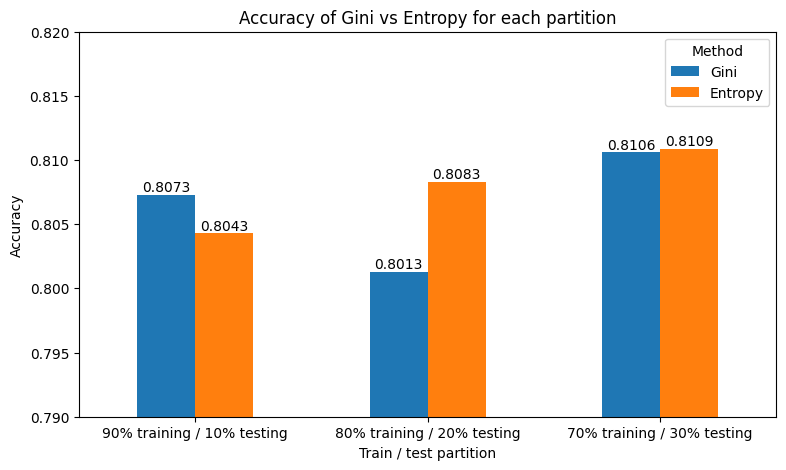

In [40]:
ax = compare_table.T.plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy of Gini vs Entropy for each partition")
plt.xlabel("Train / test partition")
plt.ylabel("Accuracy")
plt.ylim(0.79, 0.82)
plt.xticks(rotation=0)
plt.legend(title="Method")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.4f")
plt.show()

The chart shows that Gini is higher only in 90/10, while Entropy is higher in 80/20 and 70/30. Both methods reach their best accuracy with the 70/30 partition. Note that the y-axis starts at 0.79, not 0, to make the small differences visible. This makes the gaps look bigger than they really are, since all bars are between 0.80 and 0.82.

## 6.4 Clustering - K-means

In [42]:
K_VALUES = [2, 3, 4]
labels_by_k = {}

for k in K_VALUES:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    ).fit(X_cl)

    labels_by_k[k] = km.labels_

    print("K =", k,"| Silhouette Score =",round(silhouette_score(X_cl, km.labels_), 4))


K = 2 | Silhouette Score = 0.5068
K = 3 | Silhouette Score = 0.5541
K = 4 | Silhouette Score = 0.2822


K values: [2, 3, 4]
Inertias: [6009.098116496438, 4328.672747026393, 3428.802851140225]


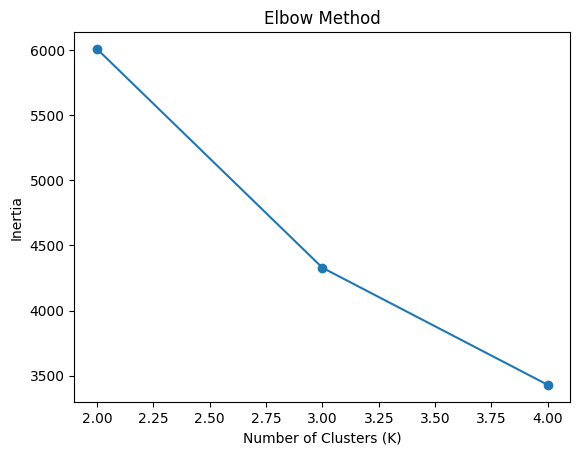

In [43]:
import matplotlib.pyplot as plt

inertias = []

for k in K_VALUES:
    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=SEED
    )
    km.fit(X_cl)
    inertias.append(km.inertia_)

print("K values:", K_VALUES)
print("Inertias:", inertias)

plt.plot(K_VALUES, inertias, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()


In [44]:
results = pd.DataFrame({
    f"K={k}": {
        "Average Silhouette width": round(silhouette_score(X_cl, labels_by_k[k]), 4),
        "Total within-cluster SS": round(inertias[i], 1)
    }
    for i, k in enumerate(K_VALUES)
})
display(results)

for k in K_VALUES:
    print("K =", k, "cluster sizes:", pd.Series(labels_by_k[k]).value_counts().sort_index().tolist())

print(X_cl.groupby(labels_by_k[4]).mean().round(2))

,K=2,K=3,K=4
Average Silhouette width,0.5068,0.5541,0.2822
Total within-cluster SS,6009.1000,4328.7000,3428.8000


K = 2 cluster sizes: [42128, 3857]
K = 3 cluster sizes: [39947, 2181, 3857]
K = 4 cluster sizes: [22670, 3856, 2181, 17278]
    age  fnlwgt  educational-num  capital-gain  capital-loss  hours-per-week
0  0.16    0.54             0.59          0.00           0.0            0.39
1  0.37    0.52             0.67          0.77           0.0            0.44
2  0.34    0.53             0.67          0.00           0.9            0.44
3  0.46    0.51             0.62          0.00           0.0            0.42


**Interpretation for each K:**

- **K = 2:** Silhouette = 0.5068. The data is split into one large cluster (42,128 records) and one cluster (3,857 records) with a high capital-gain.
- **K = 3:** Silhouette = 0.5541, the highest. A separate cluster of 2,181 records with a high capital-loss splits off from the large cluster, so the clusters are: high capital-gain, high capital-loss, and the rest.
- **K = 4:** Silhouette = 0.2822. The large group is split by age into a younger cluster (22,670 records) and an older cluster (17,278 records). This split cuts through a dense group, so the clusters are not well separated and the Silhouette drops sharply.
- **Best K (majority rule):** Silhouette gives K = 3 (highest at 0.5541), and the Elbow method also gives K = 3 because the total within-cluster sum of squares decreases more slowly after K = 3. Both measures agree, so K = 3 is the best choice.

In [45]:
BEST_K = 3

km = KMeans(n_clusters=BEST_K,n_init=10,random_state=SEED)

labels = km.fit_predict(X_cl)

print(pd.Series(labels).value_counts().sort_index())


0    39947
1     2181
2     3857
Name: count, dtype: int64


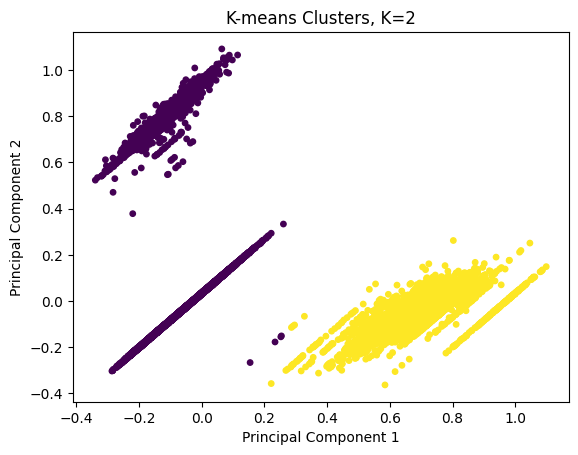

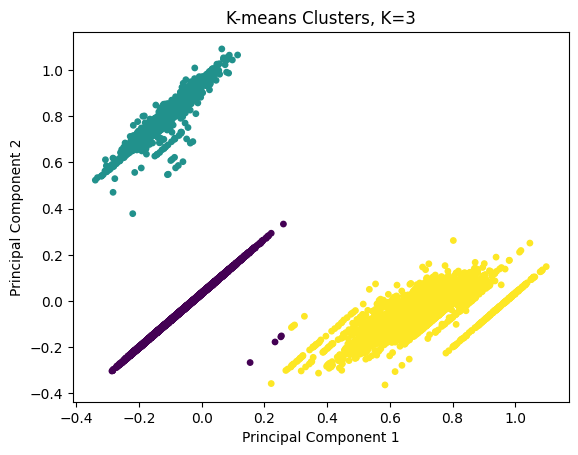

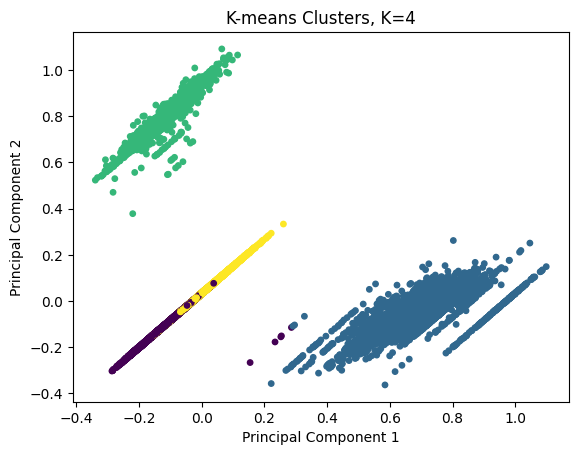

In [46]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pts = PCA(n_components=2, random_state=SEED).fit_transform(X_cl)

for k in K_VALUES:
    plt.figure()
    plt.scatter(pts[:, 0], pts[:, 1], c=labels_by_k[k], cmap='viridis', s=15)
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.title(f'K-means Clusters, K={k}')
    plt.show()

### PCA Visualization

PCA was used to reduce the numerical features to two principal components for visualization. The scatter plots show the clustering results for K = 2, K = 3, and K = 4 using different colors. The plots help visualize the clustering structure and compare the separation between clusters.

### Cluster Interpretation

Based on the Silhouette Score, K = 3 was selected as the best number of clusters, with a score of 0.5541.

The dataset was divided into three clusters:

- Cluster 0: 39,947 records.
- Cluster 1: 2,181 records.
- Cluster 2: 3,857 records.

Cluster 0 represents the largest group, while Clusters 1 and 2 contain fewer records. These results show that K-means divided the dataset into three groups of different sizes.

# [7] Findings and Discussion

## 7.1 Gini Decision Tree

In [47]:
print("Depth of the full Gini tree:", clf3.get_depth())
print("Number of leaves:", clf3.get_n_leaves())

Depth of the full Gini tree: 54
Number of leaves: 4747


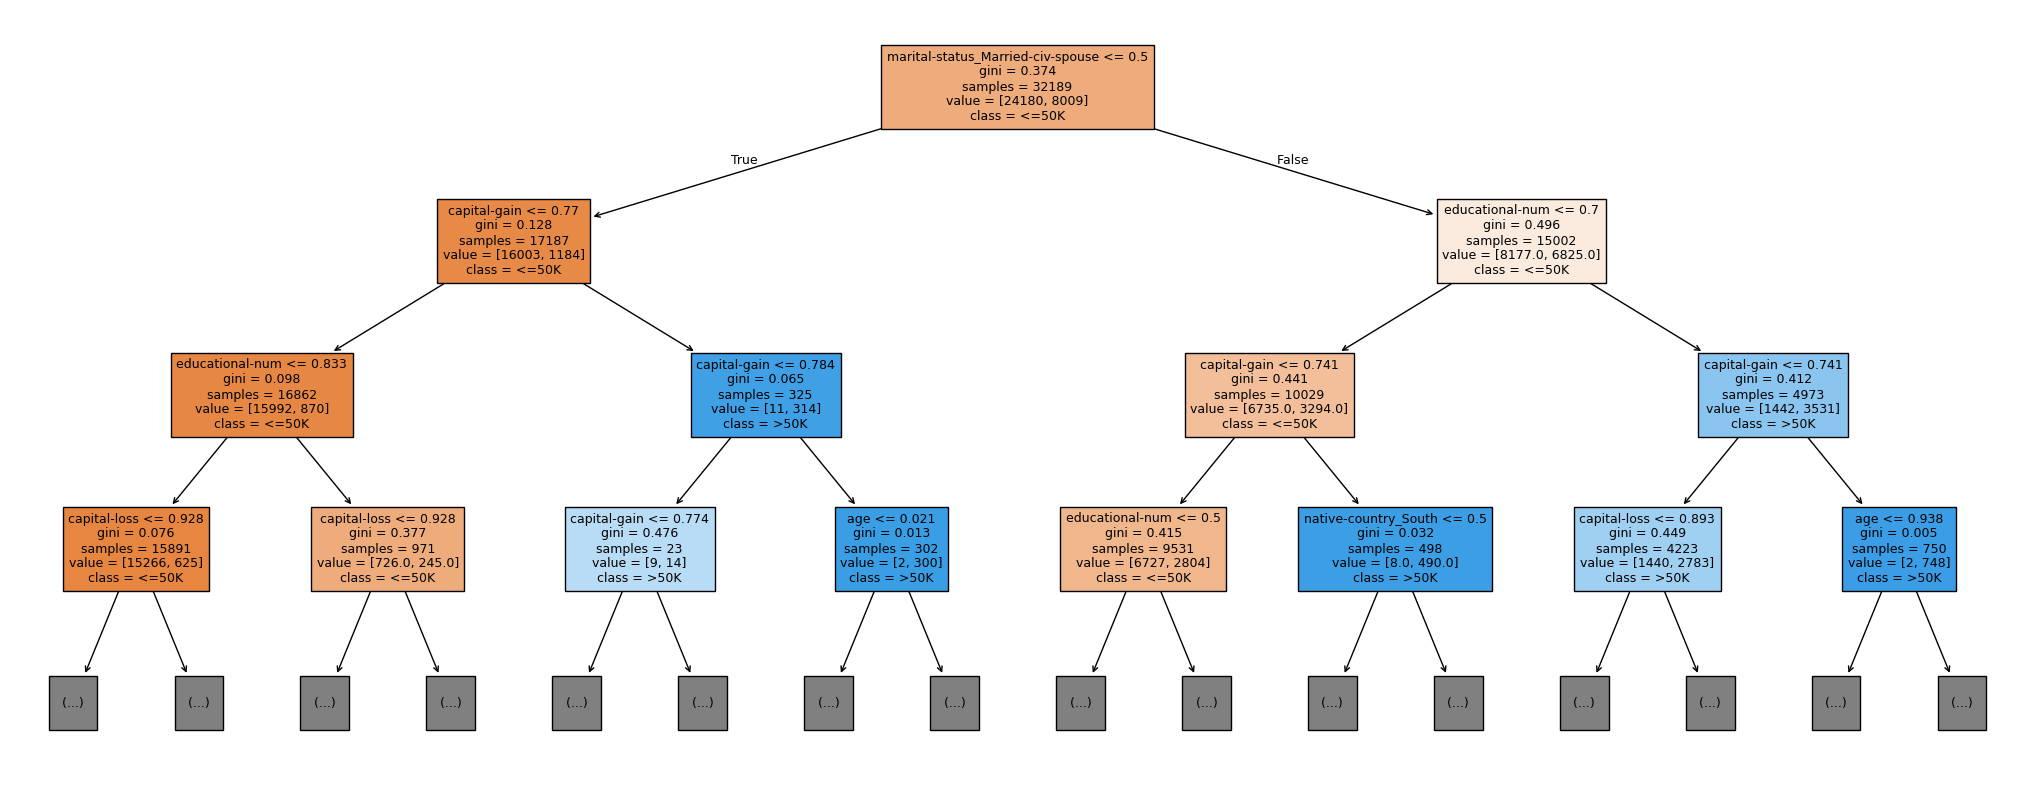

In [48]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(clf3,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3,
               fontsize=9);

fig.savefig("Gini_DT.png")

**Interpretation of the Gini tree (70/30 partition):** The root node splits on marital-status_Married-civ-spouse, so marital status is the most informative attribute. Under the non-married branch, the tree splits on capital-gain and educational-num; under the married branch, it splits on educational-num and capital-gain. This means that being married, having a higher education level, and having capital gains are the main indicators of income `>50K`. Only the top 3 levels are plotted because the full tree is too large to read.

**Limitations:** The full tree is very deep (depth 54 with 4,747 leaves), which suggests it may overfit the training data. Also, about 75% of the records belong to `<=50K`, so accuracy alone can be misleading.

## 7.2 Entropy Decision Tree

In [49]:
print("Depth of the full Entropy tree:", entropy_clf3.get_depth())
print("Number of leaves:", entropy_clf3.get_n_leaves())

Depth of the full Entropy tree: 62
Number of leaves: 4651


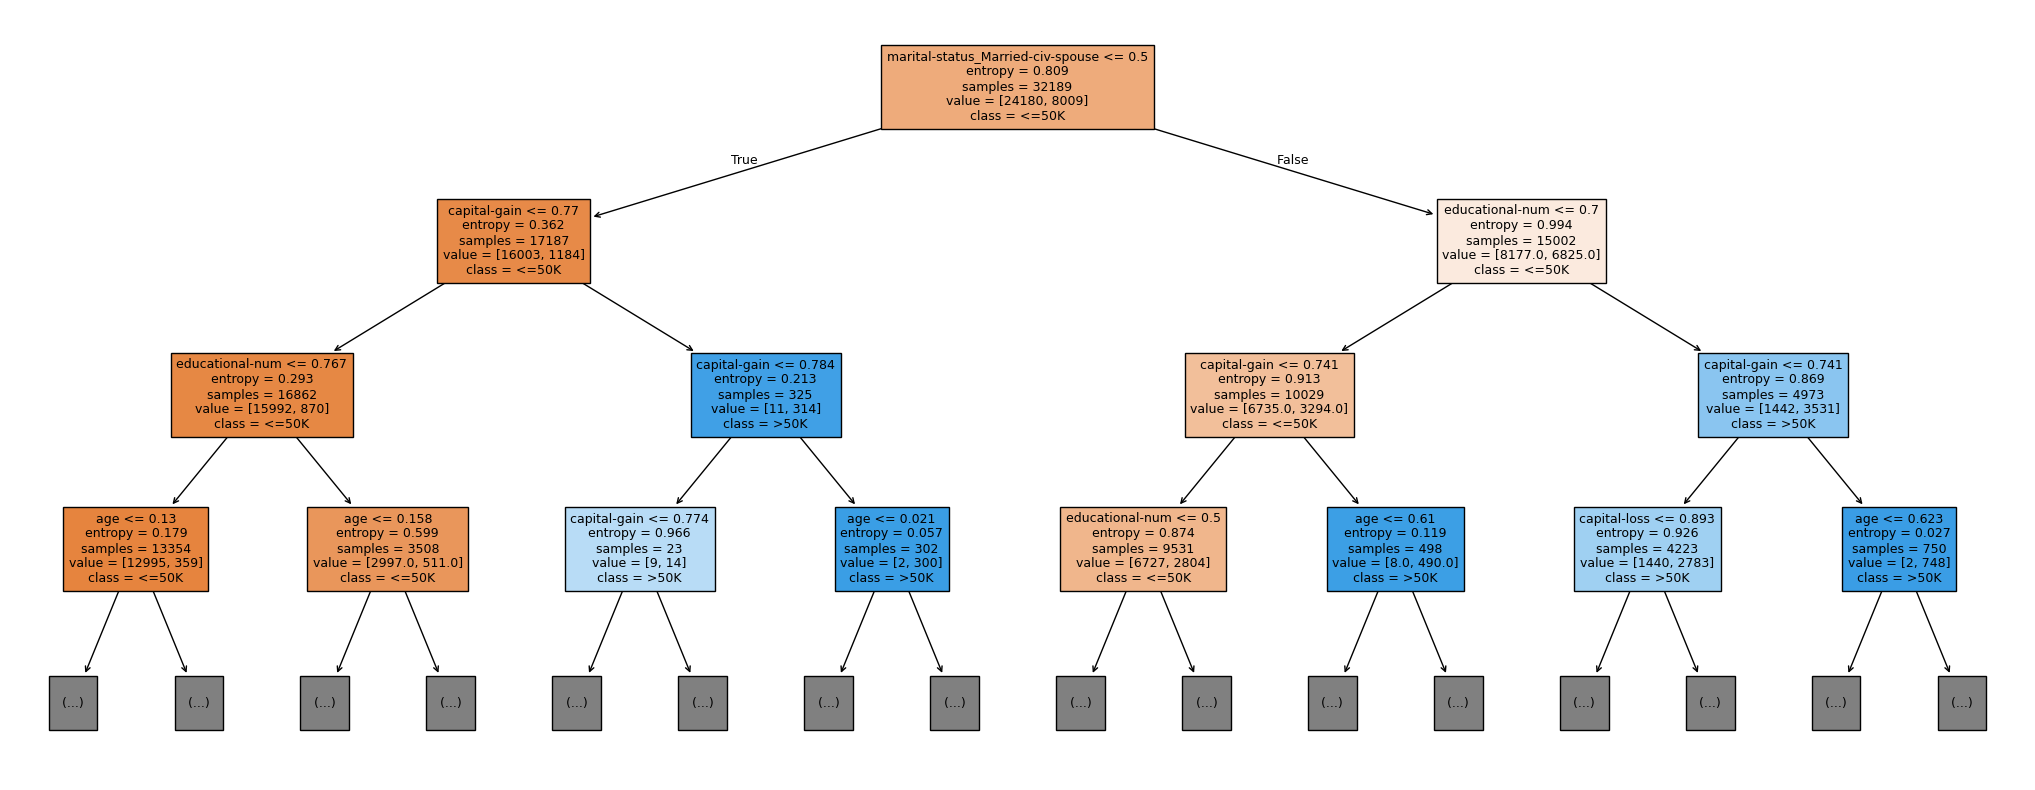

In [50]:
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(26, 10), dpi=100)

tree.plot_tree(entropy_clf3,
               feature_names=fn,
               class_names=cn,
               filled=True,
               max_depth=3,
               fontsize=9);

fig.savefig("Entropy_DT.png")

### Tree interpretation

Each box shows the split rule, the entropy of the node, the number of training records (samples), the number of records in each class (value, in the order `<=50K`, `>50K`), and the majority class. The left arrow (True) means the rule is true and the right arrow (False) means it is false. Orange boxes are mostly `<=50K` and blue boxes are mostly `>50K`; a darker color means the node is purer. Note that the numeric attributes were normalized to 0-1 in Phase 2, so the split values are on that scale.

1. **Root node:** The first split is on marital-status_Married-civ-spouse. This is a column created by get_dummies from the original attribute marital-status. It is 1 if the person is married with a civilian spouse, and 0 otherwise. The root has 32,189 training records (about 75% `<=50K`) with entropy 0.809, and this split gives the biggest information gain.

2. **Not married branch (left):** Here about 93% of the records are `<=50K`, so this group is already quite pure. The tree then splits on capital-gain: the small group with a high capital gain (about $7,000 or more in the original data, 325 records) is about 97% `>50K`. For the rest, the tree splits on educational-num (above about 12.5 on the original 1-16 scale, which means Bachelors or higher), and then on age.

3. **Married branch (right):** This group is almost 50/50 (about 55% `<=50K` and 45% `>50K`), with entropy 0.994, close to the maximum. So the tree needs more splits here. It splits on educational-num (above about 11.5, which means Assoc-acdm or higher): people with higher education are about 71% `>50K`, while the others are about 33% `>50K`. Both groups are then split on capital-gain (about $5,000 or more), and the next level uses educational-num, age and capital-loss.

4. **Upper branches:** The attributes used in the top levels are marital status, capital gain, education level (educational-num), age and capital loss.

5. **How the tree classifies income:** Following the branches, a person who is married, has a higher education level, and has a high capital gain reaches a node with 750 records where 748 are `>50K` (almost 100%). A person who is not married and has no large capital gain reaches a node with 16,862 records where about 95% are `<=50K`.


### Entropy findings and limitations

- **Best Entropy accuracy:** 81.09% with the 70/30 partition. This is also the highest accuracy among all six tested configurations, but Gini with 70/30 is only 0.03 percentage points lower (4 records).
- **Confusion matrices:** In all three partitions, the model correctly classifies about 86-87% of `<=50K` records but only about 61-62% of `>50K` records. Most errors are high-income people predicted as `<=50K`.
- **Important attributes:** Marital status (the root split), capital gain, education level and age are the main attributes used to separate the classes.
- **What the tree shows:** Being married, having a higher education level and having capital gains lead to the `>50K` class, while not being married with no large capital gain mostly leads to `<=50K`.

**Limitations:**

- The tree has no depth limit, so it grows very deep (depth 62 with 4,651 leaves). It probably overfits the training data.
- The dataset is imbalanced (about 75% `<=50K`), so accuracy alone hides the weaker performance on the `>50K` class.
- Each partition is one random split with random_state=42. The differences between Gini and Entropy are less than 1 percentage point, so a different split could change which method wins.

## 7.3 Cluster Interpretation



In [51]:
cluster_data = X_cl.copy()
cluster_data['Cluster'] = labels

print(cluster_data.groupby('Cluster').mean().round(2))

          age  fnlwgt  educational-num  capital-gain  capital-loss  \
Cluster                                                              
0        0.29    0.53             0.60          0.00           0.0   
1        0.34    0.53             0.67          0.00           0.9   
2        0.37    0.52             0.67          0.77           0.0   

         hours-per-week  
Cluster                  
0                  0.40  
1                  0.44  
2                  0.44  


In [52]:
cluster_data.groupby('Cluster')[['capital-gain', 'capital-loss']].agg(['mean', 'median', 'min', 'max']).round(2)

capital-gain                    capital-loss                 
                mean median   min   max         mean median  min  max
Cluster                                                              
0               0.00   0.00  0.00  0.41          0.0    0.0  0.0  0.0
1               0.00   0.00  0.00  0.00          0.9    0.9  0.6  1.0
2               0.77   0.77  0.41  1.00          0.0    0.0  0.0  0.0

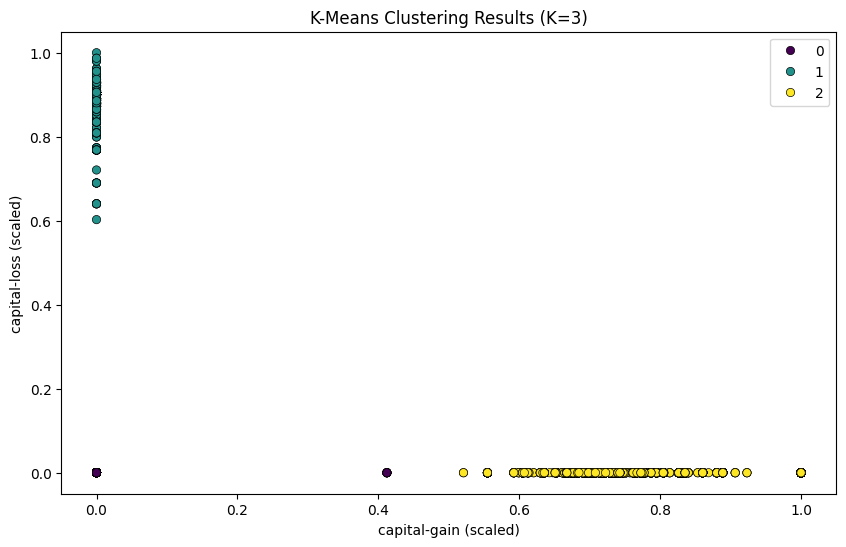

In [57]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='capital-gain', y='capital-loss', hue='Cluster',data=cluster_data, palette='viridis', edgecolor='k')
plt.title('K-Means Clustering Results (K=3)')
plt.xlabel('capital-gain (scaled)')
plt.ylabel('capital-loss (scaled)')
plt.legend()
plt.show()

### Cluster Interpretation
The scatter plot and the cluster means show that the three clusters are separated almost entirely by capital-gain and capital-loss. Cluster 2 (3,857 records) has high capital-gain (mean 0.77), Cluster 1 (2,181 records) has high capital-loss (mean 0.90), and Cluster 0 (39,947 records) has neither.

The other attributes are very similar across clusters (age 0.29 / 0.34 / 0.37, hours-per-week 0.40 / 0.44 / 0.44). So the clustering mainly isolates the small group of people with capital gains or losses, and it does not reveal broader personal profiles. This is meaningful but limited, because only the six numeric attributes were used and most people have zero capital gain and loss.

### K-means Conclusion
K-means clustering was applied to six numerical features from the preprocessed dataset, excluding the target column (income). We tested K = 2, K = 3, and K = 4 using the Silhouette Score and the Elbow Method.

K = 3 achieved the highest Silhouette Score of 0.5541, indicating better cluster separation among the tested options. The resulting clusters contained 39,947, 2,181, and 3,857 records. Overall, K = 3 was selected as the best number of clusters based on the evaluation results.

## 7.4 Overall Findings
### Classification findings

**Best model:** The Decision Tree with the **Entropy** criterion and the **70/30** partition gave the highest accuracy among the six tested configurations (**81.09%**). The Gini tree with the same partition is almost identical (**81.06%**, only 4 records behind). In all partitions the two criteria stayed between 80.1% and 81.1%, so the choice of criterion and partition size has a very small effect on this dataset.

**Class-level performance:** With the best model, 9,081 of 10,389 `<=50K` records (about 87%) were classified correctly, but only 2,106 of 3,407 `>50K` records (about 62%). The model is therefore better at recognizing the majority class, which is expected because the classes are imbalanced (about 75% `<=50K` and 25% `>50K`). Overall accuracy alone can hide this weakness.

**Information discovered:** In both trees the root node splits on marital-status_Married-civ-spouse, so being married is the most informative attribute for separating the two income classes. For non-married people the next split is on capital-gain, and for married people it is on educational-num (education level). Capital-gain, educational-num, age and capital-loss are also used in the top levels of both trees. These findings are meaningful and match what we would expect: income is linked to marital status, education, and capital gains.

**Limitation:** The trees were trained without limiting their depth (depth above 50 and thousands of leaves), so they may memorize the training data (overfitting). The tree figures show only the first three levels to stay readable.


### Comparison with the research paper

We compared our results with the paper by Chakrabarty and Biswas [1], which also predicts the income class (<=50K / >50K) on the Adult dataset using classification. The paper does not use clustering, so we compare the classification results only.

The paper reports an accuracy of 88.16% using a Gradient Boosting Classifier, while our best Decision Tree reaches 81.09%. Our result is lower, which is reasonable because Gradient Boosting combines many trees, while we use a single decision tree without tuning. The two studies also use different preprocessing, so the comparison is only approximate. Even with this difference, both studies show that the income class can be predicted reasonably well from the census attributes.

### Clustering findings

We tested K = 2, 3, and 4. K = 3 had the highest Silhouette Score (0.5541) and the Elbow plot also bends at K = 3, so it is the best number of clusters. It gave one large cluster (39,947 records) and two small clusters (2,181 and 3,857 records), which differ mainly in capital-loss and capital-gain: Cluster 1 has high capital-loss, Cluster 2 has high capital-gain, and Cluster 0 has neither. The cluster sizes are very unbalanced, and we used only the six numeric attributes.

The results are meaningful but limited: the clustering mainly isolates the small group of people with capital gains or losses, and it does not show broader groups by age, education or working hours.


# [8] References

[1] N. Chakrabarty and S. Biswas, "A statistical approach to adult census income level prediction," in *Proc. Int. Conf. Advances in Computing, Communication Control and Networking (ICACCCN)*, Greater Noida, India, 2018, pp. 207–212.

[2] wenruliu, "Adult Income Dataset," Kaggle. [Online]. Available: https://www.kaggle.com/datasets/wenruliu/adult-income-dataset (accessed Sep. 8, 2026).

[3] F. Pedregosa et al., "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

